# Student Assignment Score Prediction

This beginner-friendly notebook uses **linear regression** to predict a student's assignment score from their study hours and attendance.

## 1. Import libraries

We will use pandas for working with the data, seaborn and matplotlib for visualizations, and scikit-learn for the linear regression model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

## 2. Load the dataset

The CSV is in the `data` folder next to this notebook. The second path also supports running the notebook with the Projects folder as the working directory.

In [3]:

df = pd.read_csv("student_marks.csv")


print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (500, 4)


,Student_ID,Study_Hours,Attendance,Assignment_Score
0,S001,7.5,64,92
1,S002,7.4,91,87
2,S003,6.5,64,91
3,S004,1.7,58,52
4,S005,2.4,57,40


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        500 non-null    str    
 1   Study_Hours       500 non-null    float64
 2   Attendance        500 non-null    int64  
 3   Assignment_Score  500 non-null    int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 17.7 KB


## 3. Clean the data

Only `Study_Hours` and `Attendance` will be model inputs. `Assignment_Score` is the value we want to predict. Student ID is not used as a model input.

In [4]:
required_columns = ["Study_Hours", "Attendance", "Assignment_Score"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"The dataset is missing required columns: {missing_columns}")

rows_before_cleaning = len(df)
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

missing_rows = int(df[required_columns].isna().any(axis=1).sum())
df = df.dropna(subset=required_columns).copy()

print(f"Rows before cleaning: {rows_before_cleaning}")
print(f"Duplicate rows removed: {duplicate_rows}")
print(f"Rows with missing or invalid required values removed: {missing_rows}")
print(f"Rows after cleaning: {len(df)}")
display(df[required_columns].describe())

Rows before cleaning: 500
Duplicate rows removed: 0
Rows with missing or invalid required values removed: 0
Rows after cleaning: 500


,Study_Hours,Attendance,Assignment_Score
count,500.000000,500.000000,500.000000
mean,5.685200,70.024000,71.474000
std,2.587588,14.903276,19.874187
min,0.600000,40.000000,30.000000
25%,2.800000,58.750000,49.000000
50%,6.500000,64.000000,81.000000
75%,7.900000,87.000000,87.000000
max,10.000000,100.000000,100.000000


## 4. Explore and visualize the data

These charts show the score distribution, how each input relates to the score, and the correlations among the three numeric columns.

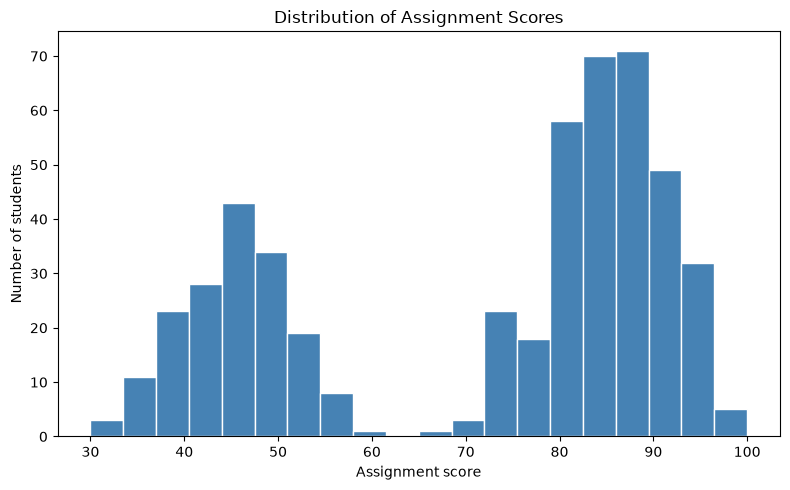

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(df["Assignment_Score"], bins=20, color="steelblue", edgecolor="white")
plt.title("Distribution of Assignment Scores")
plt.xlabel("Assignment score")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

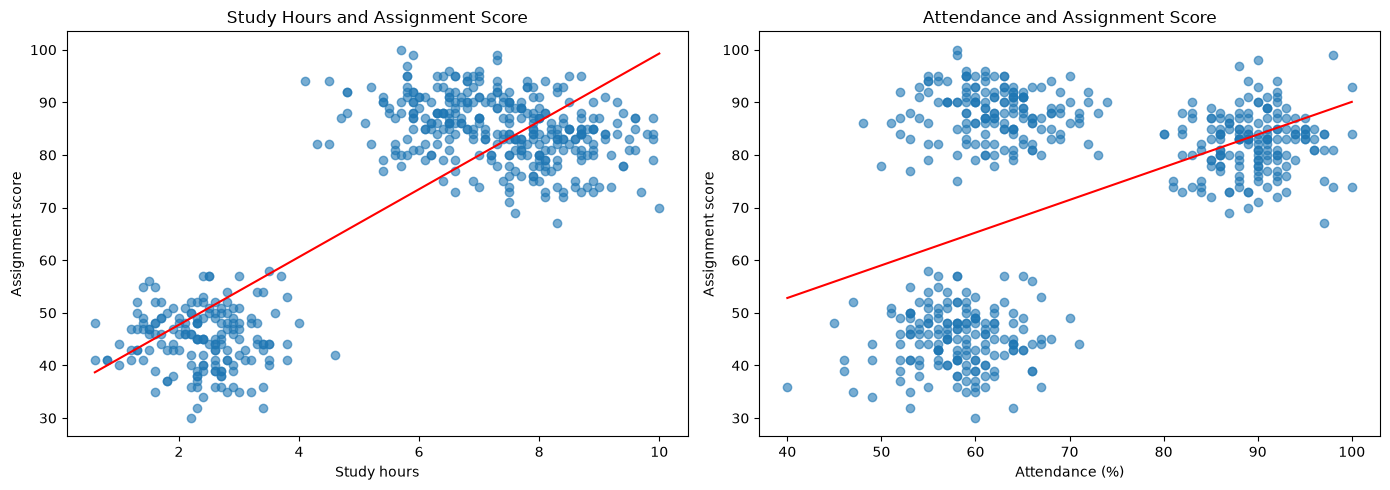

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df["Study_Hours"], df["Assignment_Score"], alpha=0.6)
study_line = np.polyfit(df["Study_Hours"], df["Assignment_Score"], 1)
study_x = np.linspace(df["Study_Hours"].min(), df["Study_Hours"].max(), 100)
axes[0].plot(study_x, np.polyval(study_line, study_x), color="red")
axes[0].set_title("Study Hours and Assignment Score")
axes[0].set_xlabel("Study hours")
axes[0].set_ylabel("Assignment score")

axes[1].scatter(df["Attendance"], df["Assignment_Score"], alpha=0.6)
attendance_line = np.polyfit(df["Attendance"], df["Assignment_Score"], 1)
attendance_x = np.linspace(df["Attendance"].min(), df["Attendance"].max(), 100)
axes[1].plot(attendance_x, np.polyval(attendance_line, attendance_x), color="red")
axes[1].set_title("Attendance and Assignment Score")
axes[1].set_xlabel("Attendance (%)")
axes[1].set_ylabel("Assignment score")

plt.tight_layout()
plt.show()

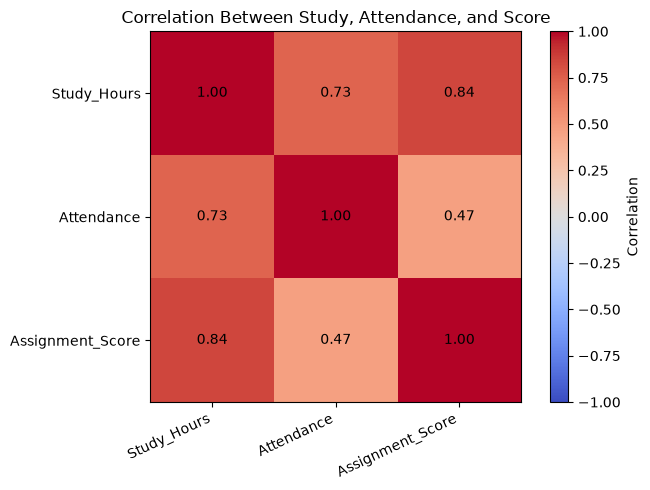

In [7]:
correlation = df[required_columns].corr()

fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(required_columns)), labels=required_columns, rotation=25, ha="right")
ax.set_yticks(range(len(required_columns)), labels=required_columns)
for row in range(len(required_columns)):
    for column in range(len(required_columns)):
        ax.text(column, row, f"{correlation.iloc[row, column]:.2f}", ha="center", va="center")
fig.colorbar(heatmap, ax=ax, label="Correlation")
ax.set_title("Correlation Between Study, Attendance, and Score")
plt.tight_layout()
plt.show()

## 5. Train the linear regression model

We hold back 20% of the data for testing. The model is trained using exactly two features: study hours and attendance.

In [8]:
features = ["Study_Hours", "Attendance"]
target = "Assignment_Score"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Intercept:", round(model.intercept_, 2))
for feature, coefficient in zip(features, model.coef_):
    print(f"{feature} coefficient: {coefficient:.2f}")

Training rows: 400
Testing rows: 100
Intercept: 53.43
Study_Hours coefficient: 8.13
Attendance coefficient: -0.40


## 6. Evaluate the model

- **MAE** is the average absolute prediction error in score points.
- **RMSE** gives more weight to larger errors and is also in score points.
- **R²** summarizes how much of the score variation is explained by the model.

In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

Mean Absolute Error (MAE): 7.71
Root Mean Squared Error (RMSE): 9.22
R-squared (R²): 0.775


## 7. Visualize model predictions and errors

Points close to the diagonal in the first chart are more accurate. Residuals are actual scores minus predicted scores.

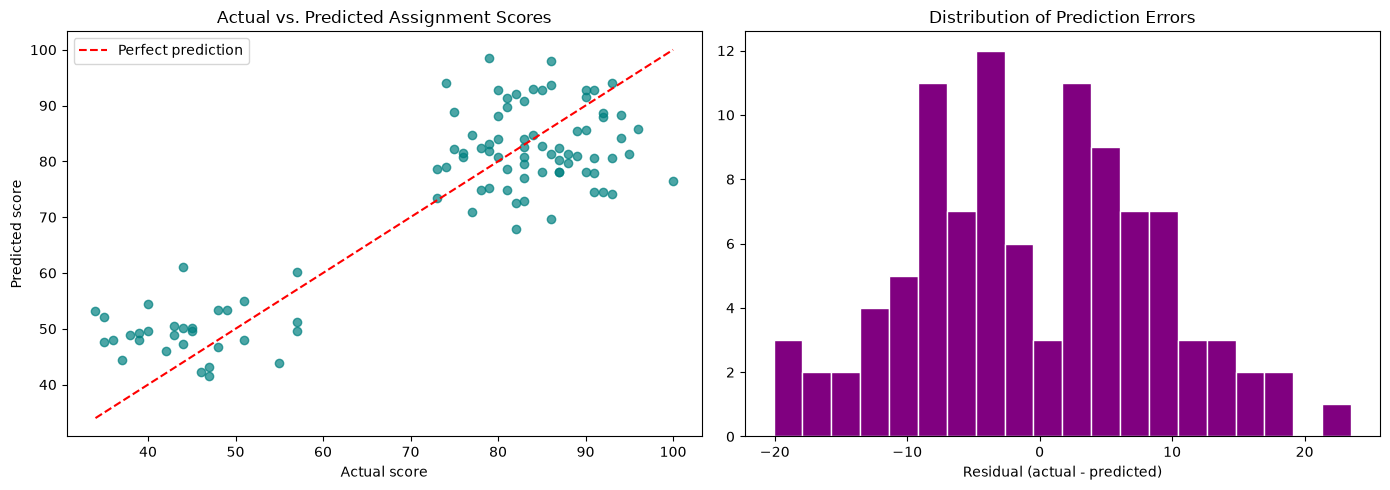

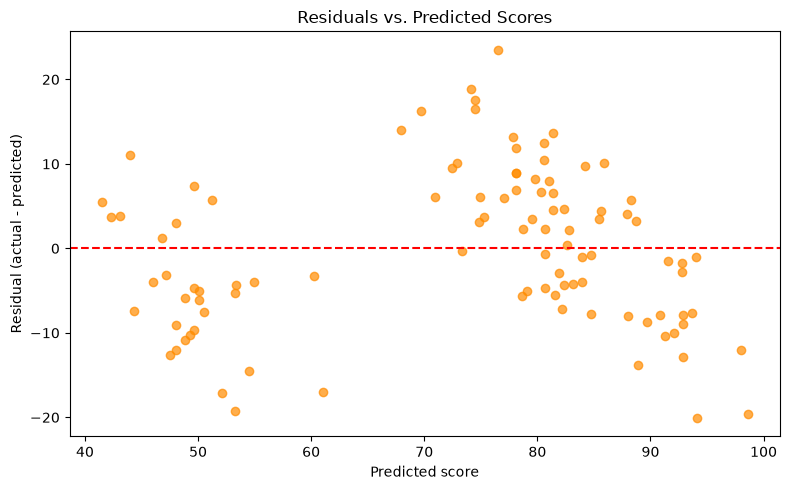

In [10]:
residuals = y_test - y_pred
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.7, color="teal")
axes[0].plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
axes[0].set_title("Actual vs. Predicted Assignment Scores")
axes[0].set_xlabel("Actual score")
axes[0].set_ylabel("Predicted score")
axes[0].legend()

axes[1].hist(residuals, bins=20, color="purple", edgecolor="white")
axes[1].set_title("Distribution of Prediction Errors")
axes[1].set_xlabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7, color="darkorange")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs. Predicted Scores")
plt.xlabel("Predicted score")
plt.ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

## 8. Predict for a new student

Change the example values below to try a different number of study hours or attendance percentage.

In [11]:
new_student = pd.DataFrame({
    "Study_Hours": [6.0],
    "Attendance": [85],
})

predicted_score = model.predict(new_student)[0]
print("Example student:")
print("Study hours: 6.0")
print("Attendance: 85%")
print(f"Predicted assignment score: {predicted_score:.2f}")

Example student:
Study hours: 6.0
Attendance: 85%
Predicted assignment score: 68.08
